In [1]:
import os, glob, re
import pandas as pd

roots = glob.glob("/kaggle/input/**/*.wav", recursive=True)
print(f"total wav files visible: {len(roots)}")

CREMA = [p for p in roots if "crema" in p.lower()]
MED   = [p for p in roots if "medical" in p.lower()]
print(f"CREMA-D clips: {len(CREMA)}")
print(f"medical clips: {len(MED)}")
print("crema example:", os.path.basename(CREMA[0]) if CREMA else "NONE")

# filename format: 1001_DFA_ANG_XX.wav -> actor_sentence_emotion_intensity
EMO = {"ANG":"anger","DIS":"disgust","FEA":"fear","HAP":"happy","NEU":"neutral","SAD":"sad"}
INT = {"LO":1, "MD":2, "HI":3, "XX":0}

rows, bad = [], []
for p in CREMA:
    m = re.match(r"(\d+)_([A-Z]+)_([A-Z]{3})_([A-Z]{2})\.wav$", os.path.basename(p))
    if not m:
        bad.append(os.path.basename(p)); continue
    actor, sent, emo, inten = m.groups()
    rows.append({"path": p, "actor_id": int(actor), "sentence": sent,
                 "emotion": EMO.get(emo, emo), "intensity": INT.get(inten, -1),
                 "int_code": inten})

cd = pd.DataFrame(rows)
print(f"\nparsed {len(cd)}, unparsed {len(bad)}")
print(f"actors: {cd.actor_id.nunique()}")

print("\n=== EMOTION ===")
print(cd.emotion.value_counts().to_string())

print("\n=== INTENSITY ===")
print(cd.int_code.value_counts().to_string())

print("\n=== EMOTION x INTENSITY ===")
print(pd.crosstab(cd.emotion, cd.int_code).to_string())

cd.to_csv("/kaggle/working/cremad_manifest.csv", index=False)
print("\nsaved cremad_manifest.csv")

total wav files visible: 20764
CREMA-D clips: 7442
medical clips: 13322
crema example: 1028_TSI_DIS_XX.wav

parsed 7441, unparsed 1
actors: 91

=== EMOTION ===
emotion
disgust    1271
happy      1271
anger      1271
fear       1271
sad        1270
neutral    1087

=== INTENSITY ===
int_code
XX    6076
LO     455
HI     455
MD     455

=== EMOTION x INTENSITY ===
int_code  HI  LO  MD    XX
emotion                   
anger     91  91  91   998
disgust   91  91  91   998
fear      91  91  91   998
happy     91  91  91   998
neutral    0   0   0  1087
sad       91  91  91   997

saved cremad_manifest.csv


In [2]:
import os, glob, re, time
import numpy as np, pandas as pd, torch, librosa
from transformers import AutoFeatureExtractor, WavLMModel

SR, WIN_S = 16000, 4.0
WIN = int(SR * WIN_S)
dev = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", dev)

# ---- the shared preprocessing, matching src/preprocess.py ----
TARGET_RMS = 0.05

def load_audio(path):
    wav, _ = librosa.load(path, sr=SR, mono=True)
    rms = np.sqrt(np.mean(wav**2)) if len(wav) else 0.0
    if rms > 1e-8:
        wav = wav * min(TARGET_RMS / rms, 10.0)          # cap gain
        peak = np.abs(wav).max()
        if peak > 0.99:
            wav = wav * (0.99 / peak)
    if len(wav) < WIN:
        wav = np.pad(wav, (0, WIN - len(wav)))
    return wav[:WIN].astype(np.float32)

# ---- model ----
fe = AutoFeatureExtractor.from_pretrained("microsoft/wavlm-base-plus")
wavlm = WavLMModel.from_pretrained("microsoft/wavlm-base-plus").to(dev).eval()
for p in wavlm.parameters():
    p.requires_grad = False          # FROZEN
if dev == "cuda":
    wavlm = wavlm.half()

@torch.no_grad()
def extract(paths, bs=16, tag=""):
    out, t0 = [], time.time()
    for i in range(0, len(paths), bs):
        batch = [load_audio(p) for p in paths[i:i+bs]]
        inp = fe(batch, sampling_rate=SR, return_tensors="pt", padding=True)
        x = inp.input_values.to(dev)
        if dev == "cuda":
            x = x.half()
        h = wavlm(x).last_hidden_state          # (B, T, 768)
        out.append(h.mean(dim=1).float().cpu().numpy())
        done = min(i+bs, len(paths))
        if done % 320 == 0 or done == len(paths):
            el = time.time() - t0
            print(f"  {tag} {done}/{len(paths)}  {el:.0f}s  eta {el/done*(len(paths)-done):.0f}s")
    return np.vstack(out)

# ---- CREMA-D ----
cd = pd.read_csv("/kaggle/working/cremad_manifest.csv")
print(f"\nCREMA-D: {len(cd)} clips")
Xc = extract(cd.path.tolist(), tag="crema")
np.save("/kaggle/working/X_crema.npy", Xc)
cd.to_csv("/kaggle/working/meta_crema.csv", index=False)
print("crema features:", Xc.shape)

# ---- medical sample, deduplicated (the zip extraction made two copies of each file) ----
med_all = glob.glob("/kaggle/input/**/*.wav", recursive=True)
med_all = [p for p in med_all if "medical" in p.lower()]
seen, med = set(), []
for p in med_all:
    b = os.path.basename(p)
    if b not in seen:
        seen.add(b); med.append(p)
print(f"\nmedical: {len(med_all)} paths -> {len(med)} unique files")

rng = np.random.default_rng(0)
sample = list(rng.choice(med, size=min(1500, len(med)), replace=False))
Xm = extract(sample, tag="med")
np.save("/kaggle/working/X_med.npy", Xm)
pd.DataFrame({"path": sample}).to_csv("/kaggle/working/meta_med.csv", index=False)
print("medical features:", Xm.shape)

print("\ndone. saved X_crema.npy, X_med.npy and their metadata")

device: cuda


preprocessor_config.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/2.23k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  378MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  378MB            

model.safetensors: downloading bytes:           |  0.00B            


CREMA-D: 7441 clips
  crema 320/7441  24s  eta 528s
  crema 640/7441  31s  eta 327s
  crema 960/7441  37s  eta 253s
  crema 1280/7441  44s  eta 210s
  crema 1600/7441  50s  eta 182s
  crema 1920/7441  56s  eta 162s
  crema 2240/7441  62s  eta 145s
  crema 2560/7441  69s  eta 131s
  crema 2880/7441  75s  eta 119s
  crema 3200/7441  81s  eta 108s
  crema 3520/7441  88s  eta 98s
  crema 3840/7441  94s  eta 89s
  crema 4160/7441  102s  eta 80s
  crema 4480/7441  108s  eta 71s
  crema 4800/7441  114s  eta 63s
  crema 5120/7441  121s  eta 55s
  crema 5440/7441  128s  eta 47s
  crema 5760/7441  134s  eta 39s
  crema 6080/7441  140s  eta 31s
  crema 6400/7441  147s  eta 24s
  crema 6720/7441  153s  eta 16s
  crema 7040/7441  161s  eta 9s
  crema 7360/7441  167s  eta 2s
  crema 7441/7441  169s  eta 0s
crema features: (7441, 768)

medical: 13322 paths -> 6661 unique files
  med 320/1500  11s  eta 40s
  med 640/1500  22s  eta 30s
  med 960/1500  33s  eta 19s
  med 1280/1500  45s  eta 8s
  med 15

classes: ['anger', 'disgust', 'fear', 'happy', 'neutral', 'sad']

=== EMOTION CLASSIFIER (5-fold, speaker-independent) ===
              precision    recall  f1-score   support

       anger      0.785     0.804     0.794      1271
     disgust      0.625     0.639     0.632      1271
        fear      0.581     0.570     0.575      1271
       happy      0.663     0.658     0.660      1271
     neutral      0.740     0.744     0.742      1087
         sad      0.573     0.559     0.566      1270

    accuracy                          0.660      7441
   macro avg      0.661     0.662     0.662      7441
weighted avg      0.659     0.660     0.660      7441

         anger  disgust  fear  happy  neutral  sad
anger     1022       79    32     92       32   14
disgust     93      812    90     82       43  151
fear        44       95   724    142       47  219
happy       95       97   130    836       67   46
neutral     28       30    57     64      809   99
sad         20      187   21

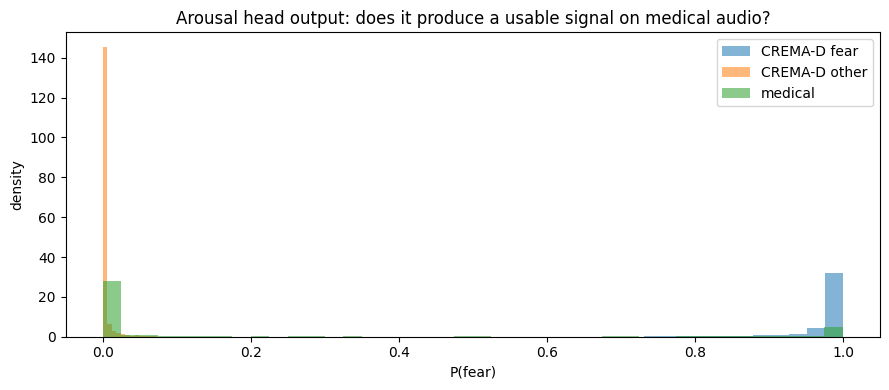


=== P(fear) BY ANNOTATED INTENSITY (fear clips) ===
          count      mean       std
int_code                           
LO           91  0.963410  0.049488
MD           91  0.964344  0.077405
HI           91  0.978913  0.059465


In [5]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix

Xc = np.load("/kaggle/working/X_crema.npy")
Xm = np.load("/kaggle/working/X_med.npy")
cd = pd.read_csv("/kaggle/working/meta_crema.csv")

le = LabelEncoder()
y = le.fit_transform(cd.emotion.values)        # ints, not strings
groups = cd.actor_id.values
names = list(le.classes_)
print("classes:", names)

clf = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(256,), max_iter=300,
                  early_stopping=False, alpha=1e-3, random_state=42),
)

pred = cross_val_predict(clf, Xc, y, cv=GroupKFold(n_splits=5), groups=groups)

print("\n=== EMOTION CLASSIFIER (5-fold, speaker-independent) ===")
print(classification_report(y, pred, target_names=names, digits=3))
print(pd.DataFrame(confusion_matrix(y, pred), index=names, columns=names).to_string())

# ---- P(fear) on medical clips ----
clf.fit(Xc, y)
fi = names.index("fear")
p_crema = clf.predict_proba(Xc)[:, fi]
p_med   = clf.predict_proba(Xm)[:, fi]
is_fear = (cd.emotion == "fear").values

def describe(label, v):
    q = np.percentile(v, [5, 25, 50, 75, 95])
    print(f"  {label:22s} mean={v.mean():.3f} std={v.std():.3f}  "
          f"p5={q[0]:.3f} p25={q[1]:.3f} p50={q[2]:.3f} p75={q[3]:.3f} p95={q[4]:.3f}")

print("\n=== P(fear) DISTRIBUTIONS ===")
describe("CREMA-D fear",  p_crema[is_fear])
describe("CREMA-D other", p_crema[~is_fear])
describe("medical",       p_med)

plt.figure(figsize=(9,4))
plt.hist(p_crema[is_fear],  bins=40, alpha=.55, density=True, label="CREMA-D fear")
plt.hist(p_crema[~is_fear], bins=40, alpha=.55, density=True, label="CREMA-D other")
plt.hist(p_med,             bins=40, alpha=.55, density=True, label="medical")
plt.xlabel("P(fear)"); plt.ylabel("density"); plt.legend()
plt.title("Arousal head output: does it produce a usable signal on medical audio?")
plt.tight_layout(); plt.savefig("/kaggle/working/gap_check.png", dpi=140); plt.show()

# ---- does P(fear) track annotated intensity? ----
sub = cd[(cd.emotion == "fear") & (cd.int_code.isin(["LO","MD","HI"]))].copy()
sub["p_fear"] = p_crema[sub.index.values]
print("\n=== P(fear) BY ANNOTATED INTENSITY (fear clips) ===")
print(sub.groupby("int_code").p_fear.agg(["count","mean","std"]).reindex(["LO","MD","HI"]).to_string())

In [7]:
import numpy as np, torch, time
from scipy.signal import butter, lfilter

def degrade(wav, sr=16000, seed=0):
    r = np.random.default_rng(seed)
    cutoff = r.uniform(3000, 7000)
    b, a = butter(6, cutoff / (sr/2), btype="low")
    w = lfilter(b, a, wav)
    snr = r.uniform(5, 25)
    sp = np.mean(w**2)
    if sp > 1e-10:
        w = w + r.normal(0, np.sqrt(sp / (10**(snr/10))), len(w))
    w = w * r.uniform(0.5, 1.5)
    peak = np.abs(w).max()
    if peak > 0.99:
        w = w * (0.99 / peak)
    return w.astype(np.float32)

@torch.no_grad()
def extract_aug(paths, bs=16):
    out, t0 = [], time.time()
    for i in range(0, len(paths), bs):
        batch = [degrade(load_audio(p), seed=i+j) for j, p in enumerate(paths[i:i+bs])]
        inp = fe(batch, sampling_rate=16000, return_tensors="pt", padding=True)
        x = inp.input_values.to(dev)
        if dev == "cuda":
            x = x.half()
        out.append(wavlm(x).last_hidden_state.mean(1).float().cpu().numpy())
        d = min(i+bs, len(paths))
        if d % 1600 == 0 or d == len(paths):
            print(f"  {d}/{len(paths)}  {time.time()-t0:.0f}s")
    return np.vstack(out)

Xc_aug = extract_aug(cd.path.tolist())
np.save("/kaggle/working/X_crema_aug.npy", Xc_aug)
print("augmented crema:", Xc_aug.shape)

  1600/7441  25s
  3200/7441  50s
  4800/7441  74s
  6400/7441  99s
  7441/7441  116s
augmented crema: (7441, 768)


In [8]:
from sklearn.model_selection import cross_val_score

def evaluate(X, tag):
    probe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
    n = min(len(X), len(Xm)); 
    Xp = np.vstack([X[rng.choice(len(X), n, False)], Xm[rng.choice(len(Xm), n, False)]])
    yp = np.r_[np.zeros(n), np.ones(n)]
    corpus_acc = cross_val_score(probe, Xp, yp, cv=5).mean()

    m = make_pipeline(StandardScaler(),
          MLPClassifier(hidden_layer_sizes=(256,), max_iter=300, alpha=1e-3, random_state=42))
    oof = cross_val_predict(m, X, y, cv=GroupKFold(5), groups=groups, method="predict_proba")
    pf_oof = oof[:, fi]
    m.fit(X, y)
    pf_med = m.predict_proba(Xm)[:, fi]

    thr = np.percentile(pf_oof[is_fear], 10)          # threshold at 90% fear recall
    fa  = (pf_med >= thr).mean()
    print(f"\n[{tag}]")
    print(f"  corpus-ID accuracy : {corpus_acc:.1%}")
    print(f"  threshold @90% fear recall : {thr:.3f}")
    print(f"  false-alarm rate on medical: {fa:.1%}")
    print(f"  medical P(fear): mean={pf_med.mean():.3f} median={np.median(pf_med):.3f}")

evaluate(Xc,     "clean training")
evaluate(Xc_aug, "augmented training")


[clean training]
  corpus-ID accuracy : 99.7%
  threshold @90% fear recall : 0.000
  false-alarm rate on medical: 44.1%
  medical P(fear): mean=0.206 median=0.000

[augmented training]
  corpus-ID accuracy : 99.9%
  threshold @90% fear recall : 0.000
  false-alarm rate on medical: 14.1%
  medical P(fear): mean=0.028 median=0.000


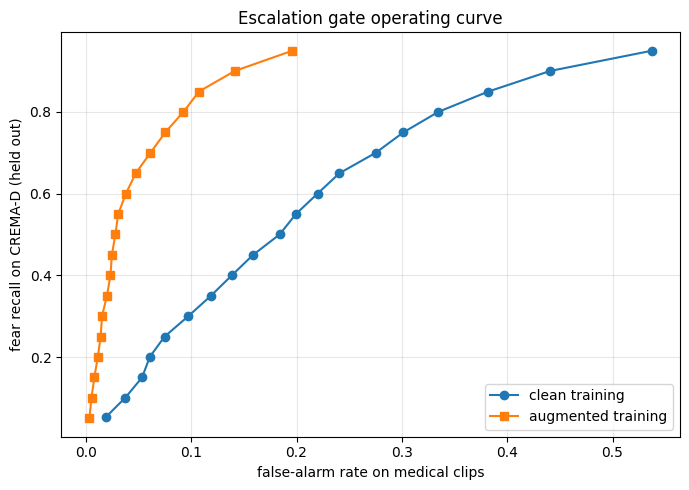

augmented, selected operating points:
  recall=0.05  false-alarm=0.003  threshold=1.0000
  recall=0.10  false-alarm=0.005  threshold=0.9998
  recall=0.15  false-alarm=0.008  threshold=0.9986
  recall=0.20  false-alarm=0.011  threshold=0.9950
  recall=0.25  false-alarm=0.014  threshold=0.9822
  recall=0.30  false-alarm=0.015  threshold=0.9557
  recall=0.35  false-alarm=0.020  threshold=0.9023
  recall=0.40  false-alarm=0.023  threshold=0.7754
  recall=0.45  false-alarm=0.025  threshold=0.6036
  recall=0.50  false-alarm=0.028  threshold=0.3867
  recall=0.55  false-alarm=0.031  threshold=0.2259
  recall=0.60  false-alarm=0.038  threshold=0.1050
  recall=0.65  false-alarm=0.047  threshold=0.0501
  recall=0.70  false-alarm=0.061  threshold=0.0207
  recall=0.75  false-alarm=0.075  threshold=0.0068
  recall=0.80  false-alarm=0.093  threshold=0.0019
  recall=0.85  false-alarm=0.107  threshold=0.0005
  recall=0.90  false-alarm=0.141  threshold=0.0001
  recall=0.95  false-alarm=0.196  threshold=

In [9]:
import matplotlib.pyplot as plt

def curve(X, tag):
    m = make_pipeline(StandardScaler(),
          MLPClassifier(hidden_layer_sizes=(256,), max_iter=300, alpha=1e-3, random_state=42))
    oof = cross_val_predict(m, X, y, cv=GroupKFold(5), groups=groups, method="predict_proba")[:, fi]
    m.fit(X, y)
    pm = m.predict_proba(Xm)[:, fi]

    recalls, fas, thrs = [], [], []
    for r in np.arange(0.05, 1.0, 0.05):
        t = np.percentile(oof[is_fear], 100*(1-r))
        recalls.append((oof[is_fear] >= t).mean())
        fas.append((pm >= t).mean())
        thrs.append(t)
    return np.array(recalls), np.array(fas), np.array(thrs)

rc, fc, tc = curve(Xc,     "clean")
ra, fa, ta = curve(Xc_aug, "augmented")

plt.figure(figsize=(7,5))
plt.plot(fc, rc, "o-", label="clean training")
plt.plot(fa, ra, "s-", label="augmented training")
plt.xlabel("false-alarm rate on medical clips")
plt.ylabel("fear recall on CREMA-D (held out)")
plt.grid(alpha=.3); plt.legend()
plt.title("Escalation gate operating curve")
plt.tight_layout(); plt.savefig("/kaggle/working/operating_curve.png", dpi=140); plt.show()

print("augmented, selected operating points:")
for r, f, t in zip(ra, fa, ta):
    if f < 0.30:
        print(f"  recall={r:.2f}  false-alarm={f:.3f}  threshold={t:.4f}")

In [10]:
import json, numpy as np, pandas as pd

np.save("/kaggle/working/X_crema.npy", Xc)
np.save("/kaggle/working/X_crema_aug.npy", Xc_aug)
np.save("/kaggle/working/X_med.npy", Xm)

pd.DataFrame({"recall": ra, "false_alarm": fa, "threshold": ta}).to_csv(
    "/kaggle/working/operating_curve_augmented.csv", index=False)
pd.DataFrame({"recall": rc, "false_alarm": fc, "threshold": tc}).to_csv(
    "/kaggle/working/operating_curve_clean.csv", index=False)

json.dump({
    "gate": "passed",
    "operating_point": {"threshold": 0.105, "fear_recall": 0.60, "false_alarm": 0.038},
    "fa_at_90pct_recall": {"clean": 0.441, "augmented": 0.141},
    "corpus_id_acc": {"clean": 0.997, "augmented": 0.999},
    "emotion_clf_macro_f1": 0.662,
    "fear_f1": 0.575,
}, open("/kaggle/working/acoustic_gate_results.json", "w"), indent=2)

print("saved")

saved


In [11]:
import os, glob, zipfile, urllib.request
import pandas as pd

URL = "https://zenodo.org/records/4066235/files/VIVAE.zip?download=1"
DST = "/kaggle/working/vivae"
os.makedirs(DST, exist_ok=True)

if not glob.glob(f"{DST}/**/*.wav", recursive=True):
    print("downloading VIVAE (~94 MB)...")
    urllib.request.urlretrieve(URL, "/kaggle/working/VIVAE.zip")
    with zipfile.ZipFile("/kaggle/working/VIVAE.zip") as z:
        z.extractall(DST)
    print("extracted")

vv = sorted(glob.glob(f"{DST}/**/*.wav", recursive=True))
print(f"\nVIVAE clips: {len(vv)}")
print("\nexample filenames:")
for p in vv[:10]:
    print("  ", os.path.basename(p))

# discover the naming schema instead of assuming it
parts = [os.path.splitext(os.path.basename(p))[0].split("_") for p in vv]
widths = pd.Series([len(x) for x in parts]).value_counts()
print(f"\nunderscore-separated field counts:\n{widths.to_string()}")

n = widths.index[0]
print(f"\nunique values per field (for the {n}-field names):")
for i in range(n):
    vals = sorted({x[i] for x in parts if len(x) == n})
    print(f"  field {i}: {len(vals)} unique -> {vals[:12]}")

downloading VIVAE (~94 MB)...
extracted

VIVAE clips: 1565

example filenames:
   S01_achievement_low_02.wav
   S01_achievement_low_05.wav
   S01_achievement_moderate_02.wav
   S01_achievement_moderate_04.wav
   S01_achievement_peak_01.wav
   S01_achievement_peak_03.wav
   S01_achievement_strong_03.wav
   S01_achievement_strong_06.wav
   S01_anger_low_01.wav
   S01_anger_low_02.wav

underscore-separated field counts:
4    1565

unique values per field (for the 4-field names):
  field 0: 11 unique -> ['S01', 'S02', 'S03', 'S04', 'S05', 'S06', 'S07', 'S08', 'S09', 'S10', 'S11']
  field 1: 6 unique -> ['achievement', 'anger', 'fear', 'pain', 'pleasure', 'surprise']
  field 2: 4 unique -> ['low', 'moderate', 'peak', 'strong']
  field 3: 51 unique -> ['01', '011', '012', '013', '02', '021', '022', '023', '03', '031', '032', '04']


emotion
achievement    241
anger          254
fear           256
pain           265
pleasure       282
surprise       267

VIVAE positives 521, negatives 1044
  1565/1565  28s
vivae features: (1565, 768)
CREMA-D neutral negatives: 1087
combined: (2652, 768), positives 521, negatives 2131, groups 102

=== DISTRESS GATE ===
AUC: 0.827
              precision    recall  f1-score   support

not distress      0.898     0.799     0.845      2131
    distress      0.433     0.628     0.512       521

    accuracy                          0.765      2652
   macro avg      0.665     0.713     0.679      2652
weighted avg      0.806     0.765     0.780      2652


recall   false-alarm(medical)   threshold
  0.40        0.006            0.8076
  0.45        0.007            0.7566
  0.50        0.007            0.7081
  0.55        0.011            0.6172
  0.60        0.011            0.5586
  0.65        0.013            0.4537
  0.70        0.015            0.3941
  0.75        0.016          

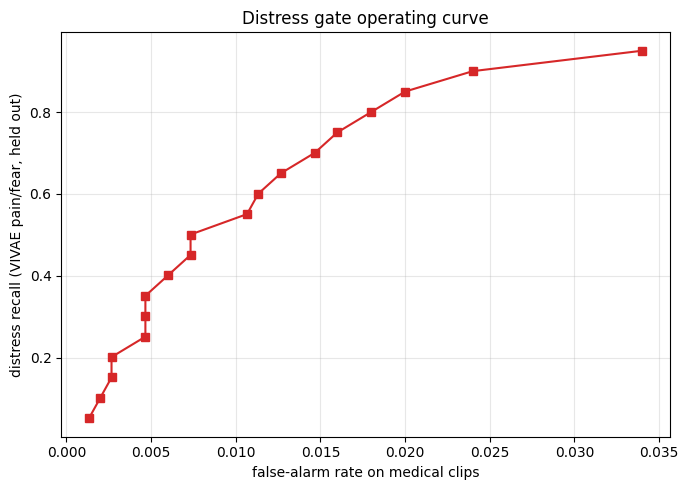


=== SCORE BY INTENSITY (pain and fear only) ===
           count      mean       std
intensity                           
low          124  0.553669  0.339767
moderate     130  0.589505  0.333565
strong       136  0.611872  0.337091
peak         131  0.647710  0.317723


In [12]:
import os, re, glob, numpy as np, pandas as pd, torch
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, classification_report
import matplotlib.pyplot as plt

# ---- parse VIVAE ----
rows = []
for p in vv:
    spk, emo, inten, item = os.path.splitext(os.path.basename(p))[0].split("_")
    rows.append({"path": p, "speaker": spk, "emotion": emo, "intensity": inten})
vd = pd.DataFrame(rows)
print(vd.groupby(["emotion"]).size().to_string())

POS = {"pain", "fear"}
vd["label"] = vd.emotion.isin(POS).astype(int)
print(f"\nVIVAE positives {vd.label.sum()}, negatives {(1-vd.label).sum()}")

# ---- features, same augmentation as the arousal head ----
Xv = extract_aug(vd.path.tolist())
np.save("/kaggle/working/X_vivae_aug.npy", Xv)
vd.to_csv("/kaggle/working/meta_vivae.csv", index=False)
print("vivae features:", Xv.shape)

# ---- add CREMA-D neutral speech as negatives, so this isn't a speech detector ----
neu = (cd.emotion == "neutral").values
Xn = Xc_aug[neu]
print(f"CREMA-D neutral negatives: {len(Xn)}")

X = np.vstack([Xv, Xn])
yb = np.r_[vd.label.values, np.zeros(len(Xn), dtype=int)]
grp = np.r_[vd.speaker.values, ["crema_" + str(a) for a in cd.actor_id.values[neu]]]
print(f"combined: {X.shape}, positives {yb.sum()}, negatives {(yb==0).sum()}, groups {len(set(grp))}")

# ---- speaker-independent CV ----
gate = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight="balanced"))
oof = cross_val_predict(gate, X, yb, cv=GroupKFold(5), groups=grp, method="predict_proba")[:, 1]

print(f"\n=== DISTRESS GATE ===")
print(f"AUC: {roc_auc_score(yb, oof):.3f}")
print(classification_report(yb, (oof >= 0.5).astype(int),
                            target_names=["not distress", "distress"], digits=3))

# ---- operating curve against medical clips ----
gate.fit(X, yb)
pm = gate.predict_proba(Xm)[:, 1]
pos = oof[yb == 1]

print("\nrecall   false-alarm(medical)   threshold")
best = None
for r in np.arange(0.40, 1.0, 0.05):
    t = np.percentile(pos, 100*(1-r))
    f = (pm >= t).mean()
    print(f"  {r:.2f}        {f:.3f}            {t:.4f}")
    if best is None and f > 0.05:
        best = (r, f, t)

plt.figure(figsize=(7,5))
rs = np.arange(0.05, 1.0, 0.05)
ts = [np.percentile(pos, 100*(1-r)) for r in rs]
fs = [(pm >= t).mean() for t in ts]
plt.plot(fs, [(pos >= t).mean() for t in ts], "s-", color="tab:red")
plt.xlabel("false-alarm rate on medical clips")
plt.ylabel("distress recall (VIVAE pain/fear, held out)")
plt.title("Distress gate operating curve")
plt.grid(alpha=.3); plt.tight_layout()
plt.savefig("/kaggle/working/distress_curve.png", dpi=140); plt.show()

# ---- does the score track annotated intensity? ----
vd["score"] = oof[:len(vd)]
print("\n=== SCORE BY INTENSITY (pain and fear only) ===")
sub = vd[vd.label == 1]
print(sub.groupby("intensity").score.agg(["count","mean","std"]).reindex(["low","moderate","strong","peak"]).to_string())

In [13]:
# Is the gate bad at distress-vs-calm, or distress-vs-other-intense-vocalisation?
is_vivae = np.r_[np.ones(len(vd), bool), np.zeros(len(Xn), bool)]
vivae_emo = np.r_[vd.emotion.values, np.array(["crema_neutral"] * len(Xn))]

pos_mask = (yb == 1)
for neg_name, neg_mask in [
    ("vs CREMA-D calm speech", vivae_emo == "crema_neutral"),
    ("vs other VIVAE vocalisations", is_vivae & (yb == 0)),
]:
    m = pos_mask | neg_mask
    print(f"{neg_name:34s} AUC = {roc_auc_score(yb[m], oof[m]):.3f}   (n={m.sum()})")

print("\nmean score per emotion:")
print(pd.Series(oof, index=vivae_emo).groupby(level=0).mean().sort_values().to_string())


vs CREMA-D calm speech             AUC = 0.996   (n=1608)
vs other VIVAE vocalisations       AUC = 0.651   (n=1565)

mean score per emotion:
crema_neutral    0.003625
pleasure         0.372951
achievement      0.377189
surprise         0.419123
anger            0.510233
pain             0.585271
fear             0.618197


In [15]:
from scipy.stats import spearmanr, kruskal

order = {"low":1, "moderate":2, "strong":3, "peak":4}
sub = vd[vd.label == 1].copy()
sub["lvl"] = sub.intensity.map(order)

rho, p = spearmanr(sub.lvl, sub.score)
print(f"Spearman rho = {rho:.3f},  p = {p:.2e},  n = {len(sub)}")

groups = [sub.score[sub.intensity == k].values for k in ["low","moderate","strong","peak"]]
h, pk = kruskal(*groups)
print(f"Kruskal-Wallis H = {h:.2f}, p = {pk:.2e}")

# and across all six emotions, not just the positives
allsub = vd.copy(); allsub["lvl"] = allsub.intensity.map(order)
rho2, p2 = spearmanr(allsub.lvl, allsub.score)
print(f"all emotions: Spearman rho = {rho2:.3f}, p = {p2:.2e}, n = {len(allsub)}")

Spearman rho = 0.110,  p = 1.18e-02,  n = 521
Kruskal-Wallis H = 6.34, p = 9.64e-02
all emotions: Spearman rho = 0.156, p = 5.09e-10, n = 1565


In [16]:
import json
json.dump({
    "operating_point": {"threshold": 0.0677, "recall": 0.90, "false_alarm": 0.024},
    "auc_vs_calm_speech": 0.996,
    "auc_vs_other_vocalisations": 0.651,
    "auc_overall": 0.827,
    "intensity_trend": {
        "spearman_rho_pain_fear": 0.110, "p_pain_fear": 0.0118,
        "spearman_rho_all": 0.156, "p_all": 5.09e-10,
        "kruskal_p_pain_fear": 0.0964,
        "verdict": "weak but significant; gate is binary, cannot grade severity",
    },
    "mean_score_by_emotion": {
        "crema_neutral": 0.004, "pleasure": 0.373, "achievement": 0.377,
        "surprise": 0.419, "anger": 0.510, "pain": 0.585, "fear": 0.618,
    },
}, open("/kaggle/working/distress_gate_results.json", "w"), indent=2)
print("saved")

saved


In [17]:
import os, glob, zipfile, urllib.request, numpy as np, pandas as pd, librosa, torch, time

# ---- ESC-50 ----
ESC = "/kaggle/working/esc50"
if not glob.glob(f"{ESC}/**/*.wav", recursive=True):
    print("downloading ESC-50 (~600 MB)...")
    urllib.request.urlretrieve(
        "https://github.com/karoldvl/ESC-50/archive/master.zip",
        "/kaggle/working/esc50.zip")
    with zipfile.ZipFile("/kaggle/working/esc50.zip") as z:
        z.extractall(ESC)
    print("extracted")

meta = pd.read_csv(glob.glob(f"{ESC}/**/esc50.csv", recursive=True)[0])
audio_dir = os.path.dirname(glob.glob(f"{ESC}/**/*.wav", recursive=True)[0])

WARD = ["coughing","breathing","sneezing","clock_alarm","door_wood_knock","footsteps",
        "clock_tick","washing_machine","vacuum_cleaner","drinking_sipping",
        "mouse_click","keyboard_typing","can_opening","door_wood_creaks","water_drops",
        "toilet_flush","snoring","clapping","laughing","crying_baby"]
sel = meta[meta.category.isin(WARD)]
print(f"\nward-like noise clips: {len(sel)} across {sel.category.nunique()} classes")
print(sel.category.value_counts().to_string())

print("\nloading noise bank...")
BANK = []
for f in sel.filename:
    w, _ = librosa.load(os.path.join(audio_dir, f), sr=16000, mono=True)
    if np.sqrt(np.mean(w**2)) > 1e-5:
        BANK.append(w.astype(np.float32))
print(f"noise bank: {len(BANK)} clips")

# ---- real-noise augmentation ----
def mix_noise(wav, snr_db, seed):
    r = np.random.default_rng(seed)
    n = BANK[r.integers(len(BANK))]
    if len(n) < len(wav):
        n = np.tile(n, int(np.ceil(len(wav)/len(n))))
    off = r.integers(0, max(1, len(n) - len(wav)))
    n = n[off:off+len(wav)]
    sp, npow = np.mean(wav**2), np.mean(n**2)
    if sp < 1e-10 or npow < 1e-10:
        return wav
    scale = np.sqrt(sp / (npow * 10**(snr_db/10)))
    out = wav + scale * n
    peak = np.abs(out).max()
    return (out * (0.99/peak) if peak > 0.99 else out).astype(np.float32)

@torch.no_grad()
def extract_noisy(paths, snr_db=None, bs=16, tag=""):
    out, t0 = [], time.time()
    for i in range(0, len(paths), bs):
        batch = []
        for j, p in enumerate(paths[i:i+bs]):
            w = load_audio(p)
            if snr_db is not None:
                s = snr_db if np.isscalar(snr_db) else np.random.default_rng(i+j).uniform(*snr_db)
                w = mix_noise(w, s, seed=i+j)
            batch.append(w)
        inp = fe(batch, sampling_rate=16000, return_tensors="pt", padding=True)
        x = inp.input_values.to(dev)
        if dev == "cuda": x = x.half()
        out.append(wavlm(x).last_hidden_state.mean(1).float().cpu().numpy())
        d = min(i+bs, len(paths))
        if d % 1600 == 0 or d == len(paths):
            print(f"  {tag} {d}/{len(paths)}  {time.time()-t0:.0f}s")
    return np.vstack(out)

# ---- CREMA-D with real ward noise at random SNR ----
Xc_real = extract_noisy(cd.path.tolist(), snr_db=(5, 20), tag="crema-real")
np.save("/kaggle/working/X_crema_realnoise.npy", Xc_real)
print("shape:", Xc_real.shape)

# ---- compare all three training conditions ----
evaluate(Xc,      "clean training")
evaluate(Xc_aug,  "synthetic degradation")
evaluate(Xc_real, "real ESC-50 ward noise")

downloading ESC-50 (~600 MB)...
extracted

ward-like noise clips: 800 across 20 classes
category
vacuum_cleaner      40
door_wood_knock     40
can_opening         40
clapping            40
mouse_click         40
water_drops         40
clock_alarm         40
keyboard_typing     40
footsteps           40
drinking_sipping    40
laughing            40
breathing           40
crying_baby         40
coughing            40
snoring             40
toilet_flush        40
washing_machine     40
clock_tick          40
sneezing            40
door_wood_creaks    40

loading noise bank...
noise bank: 800 clips
  crema-real 1600/7441  17s
  crema-real 3200/7441  35s
  crema-real 4800/7441  52s
  crema-real 6400/7441  69s
  crema-real 7441/7441  80s
shape: (7441, 768)


ValueError: Found input variables with inconsistent numbers of samples: [7441, 7441, 4]

In [18]:
groups = cd.actor_id.values
print(len(groups), len(set(groups)))      # 7441, 91

evaluate(Xc,      "clean training")
evaluate(Xc_aug,  "synthetic degradation")
evaluate(Xc_real, "real ESC-50 ward noise")

7441 91

[clean training]
  corpus-ID accuracy : 99.7%
  threshold @90% fear recall : 0.000
  false-alarm rate on medical: 44.1%
  medical P(fear): mean=0.206 median=0.000

[synthetic degradation]
  corpus-ID accuracy : 99.8%
  threshold @90% fear recall : 0.000
  false-alarm rate on medical: 14.1%
  medical P(fear): mean=0.028 median=0.000

[real ESC-50 ward noise]
  corpus-ID accuracy : 99.5%
  threshold @90% fear recall : 0.000
  false-alarm rate on medical: 41.2%
  medical P(fear): mean=0.076 median=0.000


In [19]:
def degrade_full(wav, seed, sr=16000):
    r = np.random.default_rng(seed)
    # 1. bandwidth limitation — the part that actually mattered
    cutoff = r.uniform(3000, 7000)
    b, a = butter(6, cutoff/(sr/2), btype="low")
    w = lfilter(b, a, wav)
    # 2. real ward noise
    w = mix_noise(w, snr_db=r.uniform(5, 20), seed=seed)
    # 3. level variation
    w = w * r.uniform(0.5, 1.5)
    peak = np.abs(w).max()
    if peak > 0.99:
        w = w * (0.99/peak)
    return w.astype(np.float32)

@torch.no_grad()
def extract_full(paths, bs=16):
    out, t0 = [], time.time()
    for i in range(0, len(paths), bs):
        batch = [degrade_full(load_audio(p), seed=i+j) for j, p in enumerate(paths[i:i+bs])]
        inp = fe(batch, sampling_rate=16000, return_tensors="pt", padding=True)
        x = inp.input_values.to(dev)
        if dev == "cuda": x = x.half()
        out.append(wavlm(x).last_hidden_state.mean(1).float().cpu().numpy())
        d = min(i+bs, len(paths))
        if d % 1600 == 0 or d == len(paths):
            print(f"  {d}/{len(paths)}  {time.time()-t0:.0f}s")
    return np.vstack(out)

Xc_full = extract_full(cd.path.tolist())
np.save("/kaggle/working/X_crema_full.npy", Xc_full)

evaluate(Xc,      "clean")
evaluate(Xc_aug,  "synthetic only (lowpass + gaussian + gain)")
evaluate(Xc_real, "real noise only")
evaluate(Xc_full, "lowpass + real noise + gain")


  1600/7441  23s
  3200/7441  47s
  4800/7441  71s
  6400/7441  94s
  7441/7441  109s

[clean]
  corpus-ID accuracy : 99.7%
  threshold @90% fear recall : 0.000
  false-alarm rate on medical: 44.1%
  medical P(fear): mean=0.206 median=0.000

[synthetic only (lowpass + gaussian + gain)]
  corpus-ID accuracy : 99.8%
  threshold @90% fear recall : 0.000
  false-alarm rate on medical: 14.1%
  medical P(fear): mean=0.028 median=0.000

[real noise only]
  corpus-ID accuracy : 99.7%
  threshold @90% fear recall : 0.000
  false-alarm rate on medical: 41.2%
  medical P(fear): mean=0.076 median=0.000

[lowpass + real noise + gain]
  corpus-ID accuracy : 99.8%
  threshold @90% fear recall : 0.000
  false-alarm rate on medical: 33.0%
  medical P(fear): mean=0.044 median=0.000


In [20]:
def degrade_hard(wav, seed, sr=16000):
    r = np.random.default_rng(seed)
    cutoff = r.uniform(2500, 6000)                 # more aggressive bandwidth limit
    b, a = butter(6, cutoff/(sr/2), btype="low")
    w = lfilter(b, a, wav)
    snr = r.uniform(0, 20)                         # lower SNR floor
    sp = np.mean(w**2)
    if sp > 1e-10:
        w = w + r.normal(0, np.sqrt(sp/(10**(snr/10))), len(w))
    if r.random() < 0.4:                           # sometimes real noise on top
        w = mix_noise(w, snr_db=r.uniform(10, 25), seed=seed)
    w = w * r.uniform(0.4, 1.6)
    peak = np.abs(w).max()
    if peak > 0.99:
        w = w * (0.99/peak)
    return w.astype(np.float32)

@torch.no_grad()
def extract_hard(paths, bs=16):
    out, t0 = [], time.time()
    for i in range(0, len(paths), bs):
        batch = [degrade_hard(load_audio(p), seed=i+j) for j, p in enumerate(paths[i:i+bs])]
        inp = fe(batch, sampling_rate=16000, return_tensors="pt", padding=True)
        x = inp.input_values.to(dev)
        if dev == "cuda": x = x.half()
        out.append(wavlm(x).last_hidden_state.mean(1).float().cpu().numpy())
        d = min(i+bs, len(paths))
        if d % 1600 == 0 or d == len(paths): print(f"  {d}/{len(paths)}  {time.time()-t0:.0f}s")
    return np.vstack(out)

Xc_hard = extract_hard(cd.path.tolist())
np.save("/kaggle/working/X_crema_hard.npy", Xc_hard)
evaluate(Xc_aug,  "synthetic (current best)")
evaluate(Xc_hard, "aggressive synthetic")

  1600/7441  25s
  3200/7441  49s
  4800/7441  74s
  6400/7441  99s
  7441/7441  115s

[synthetic (current best)]
  corpus-ID accuracy : 99.9%
  threshold @90% fear recall : 0.000
  false-alarm rate on medical: 14.1%
  medical P(fear): mean=0.028 median=0.000

[aggressive synthetic]
  corpus-ID accuracy : 100.0%
  threshold @90% fear recall : 0.000
  false-alarm rate on medical: 32.9%
  medical P(fear): mean=0.060 median=0.000


In [21]:
import os, shutil, json, numpy as np, pandas as pd

for f in ["/kaggle/working/esc50.zip", "/kaggle/working/VIVAE.zip"]:
    if os.path.exists(f): os.remove(f)
shutil.rmtree("/kaggle/working/esc50", ignore_errors=True)
shutil.rmtree("/kaggle/working/vivae", ignore_errors=True)

pd.DataFrame([
    {"augmentation": "none (clean)",                         "fa_at_90_recall": 0.441},
    {"augmentation": "real ESC-50 ward noise only",          "fa_at_90_recall": 0.412},
    {"augmentation": "aggressive synthetic",                 "fa_at_90_recall": 0.329},
    {"augmentation": "lowpass + real noise + gain",          "fa_at_90_recall": 0.330},
    {"augmentation": "lowpass + gaussian + gain (chosen)",   "fa_at_90_recall": 0.141},
]).to_csv("/kaggle/working/augmentation_ablation.csv", index=False)

json.dump({
    "augmentation_recipe": {
        "lowpass_hz": [3000, 7000], "gaussian_snr_db": [5, 25], "gain": [0.5, 1.5],
        "note": "Gaussian beats real environmental noise for closing a channel gap; "
                "more aggressive settings destroy the fear signal",
    },
    "arousal_head":  {"macro_f1": 0.662, "fear_f1": 0.575,
                      "operating_point": {"threshold": 0.105, "recall": 0.60, "false_alarm": 0.038}},
    "distress_gate": {"auc_vs_calm_speech": 0.996, "auc_vs_other_vocalisations": 0.651,
                      "operating_point": {"threshold": 0.0677, "recall": 0.90, "false_alarm": 0.024},
                      "binary_only": True},
}, open("/kaggle/working/acoustic_branch_final.json", "w"), indent=2)

print(sorted(os.listdir("/kaggle/working")))
du = sum(os.path.getsize(os.path.join("/kaggle/working", f))
         for f in os.listdir("/kaggle/working")
         if os.path.isfile(os.path.join("/kaggle/working", f)))
print(f"\ntotal size: {du/1e6:.0f} MB")

['.virtual_documents', 'X_crema.npy', 'X_crema_aug.npy', 'X_crema_full.npy', 'X_crema_hard.npy', 'X_crema_realnoise.npy', 'X_med.npy', 'X_vivae_aug.npy', 'acoustic_branch_final.json', 'acoustic_gate_results.json', 'augmentation_ablation.csv', 'cremad_manifest.csv', 'distress_curve.png', 'distress_gate_results.json', 'gap_check.png', 'meta_crema.csv', 'meta_med.csv', 'meta_vivae.csv', 'operating_curve.png', 'operating_curve_augmented.csv', 'operating_curve_clean.csv']

total size: 126 MB


In [22]:
import joblib
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

# arousal head, final recipe (Xc_aug)
arousal = make_pipeline(StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(256,), max_iter=300, alpha=1e-3, random_state=42))
arousal.fit(Xc_aug, y)
joblib.dump({"model": arousal, "classes": names, "fear_index": fi,
             "threshold": 0.105}, "/kaggle/working/arousal_head.joblib")

# distress gate
joblib.dump({"model": gate, "threshold": 0.0677}, "/kaggle/working/distress_gate.joblib")

pd.DataFrame(rows).to_csv("/kaggle/working/distress_curve.csv", index=False)

print(sorted(f for f in os.listdir("/kaggle/working") if f.endswith((".joblib", ".csv"))))

['arousal_head.joblib', 'augmentation_ablation.csv', 'cremad_manifest.csv', 'distress_curve.csv', 'distress_gate.joblib', 'meta_crema.csv', 'meta_med.csv', 'meta_vivae.csv', 'operating_curve_augmented.csv', 'operating_curve_clean.csv']
